In [2]:
import pandas as pd
import numpy as np
import re
import unicodedata

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
train = pd.read_csv("train.csv")
val = pd.read_csv("validation.csv")
test = pd.read_csv("test.csv")

print("Training shape:", train.shape)
print("Validation shape:", val.shape)
print("Testing shape:", test.shape)

print(train.head())


Training shape: (300, 13)
Validation shape: (75, 7)
Testing shape: (75, 7)
                                             comment             video_id  \
0  Traditional recipe super, but ingredients avai...  synthetic_augmented   
1  “Mee istam, meeku emkavalante adhi chesipedath...          YdYiIz_1vhU   
2   చాలా ఎక్కువ నూనె వేశారు, ఆరోగ్యానికి మంచిది కాదు  synthetic_augmented   
3                     Nijangaa 6hrs udaka bettalaa 😮          xDAy-L7EI5s   
4  మీరు చూపించిన process నచ్చింది, కానీ exact tim...  synthetic_augmented   

  sentiment                                  annotation_status sentiment_auto  \
0       NaN                                 Needs human review          Mixed   
1     Mixed  Auto-labelled by keyword/context heuristic; re...          Mixed   
2       NaN                                 Needs human review       Negative   
3  Positive  Auto-labelled fallback (no clear cue); review ...       Positive   
4       NaN                                 Needs human r

In [4]:
def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    text = str(text)

    # Unicode normalization
    text = unicodedata.normalize("NFC", text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Keep English, Telugu, numbers, spaces and emojis
    text = re.sub(
        r"[^a-zA-Z0-9\u0C00-\u0C7F\s\U0001F300-\U0001FAFF]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [5]:
train["cleaned_comment"] = train["comment"].apply(clean_text)
val["cleaned_comment"] = val["comment"].apply(clean_text)
test["cleaned_comment"] = test["comment"].apply(clean_text)

print(train[["comment", "cleaned_comment"]].head(10))


                                             comment  \
0  Traditional recipe super, but ingredients avai...   
1  “Mee istam, meeku emkavalante adhi chesipedath...   
2   చాలా ఎక్కువ నూనె వేశారు, ఆరోగ్యానికి మంచిది కాదు   
3                     Nijangaa 6hrs udaka bettalaa 😮   
4  మీరు చూపించిన process నచ్చింది, కానీ exact tim...   
5  పాటలు బాగున్నాయి, అయితే cooking మీద ఇంకాస్త fo...   
6    చాలా unnecessary jokes, main topic miss ayyindi   
7       వీడియో thumbnail కి content కి సంబంధం తక్కువ   
8        చాలా మంచి వంటకం, మా అమ్మ కూడా try చేస్తుంది   
9                 వంట మధ్యలో ingredients మర్చిపోయారు   

                                     cleaned_comment  
0  traditional recipe super but ingredients avail...  
1  mee istam meeku emkavalante adhi chesipedathan...  
2    చాలా ఎక్కువ నూనె వేశారు ఆరోగ్యానికి మంచిది కాదు  
3                     nijangaa 6hrs udaka bettalaa 😮  
4  మీరు చూపించిన process నచ్చింది కానీ exact timi...  
5  పాటలు బాగున్నాయి అయితే cooking మీద ఇంకాస్త foc... 

In [6]:
train = train[train["cleaned_comment"].str.strip() != ""].copy()
val = val[val["cleaned_comment"].str.strip() != ""].copy()
test = test[test["cleaned_comment"].str.strip() != ""].copy()

In [7]:
X_train = train["cleaned_comment"]
y_train = train["sentiment_auto"]

X_val = val["cleaned_comment"]
y_val = val["sentiment_auto"]

X_test = test["cleaned_comment"]
y_test = test["sentiment_auto"]

In [8]:
label_mapping = {
    "Negative": 0,
    "Mixed": 1,
    "Positive": 2
}

y_train = y_train.map(label_mapping).values
y_val = y_val.map(label_mapping).values
y_test = y_test.map(label_mapping).values

print("Negative = 0")
print("Mixed = 1")
print("Positive = 2")

Negative = 0
Mixed = 1
Positive = 2


In [9]:
vocab_size = 10000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn vocabulary only from training comments
tokenizer.fit_on_texts(X_train)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print(X_train_seq[:5])

[[134, 4, 7, 6, 24, 363, 205], [25, 364, 365, 366, 367, 368, 206, 135, 369, 370, 371, 136, 94, 372, 68, 207, 373, 374, 48, 208, 32, 375, 32, 376, 377, 208], [5, 39, 95, 378, 379, 209, 210], [380, 381, 382, 383, 384], [10, 211, 57, 33, 2, 137, 212, 11]]


In [10]:
sequence_lengths = [len(seq) for seq in X_train_seq]

max_length = int(np.percentile(sequence_lengths, 95))

print("95th percentile sequence length:", max_length)

95th percentile sequence length: 18


In [11]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training:", X_train_pad.shape)
print("Validation:", X_val_pad.shape)
print("Testing:", X_test_pad.shape)

Training: (300, 18)
Validation: (75, 18)
Testing: (75, 18)


In [12]:
np.save("X_train.npy", X_train_pad)
np.save("X_val.npy", X_val_pad)
np.save("X_test.npy", X_test_pad)

np.save("y_train.npy", y_train)
np.save("y_val.npy", y_val)
np.save("y_test.npy", y_test)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


In [13]:
print("Training data:", X_train_pad.shape)
print("Validation data:", X_val_pad.shape)
print("Testing data:", X_test_pad.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

print("Vocabulary size:", len(tokenizer.word_index))
print("Maximum sequence length:", max_length)

Training data: (300, 18)
Validation data: (75, 18)
Testing data: (75, 18)
Training labels: (300,)
Validation labels: (75,)
Testing labels: (75,)
Vocabulary size: 1213
Maximum sequence length: 18


In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Model parameters
vocab_size = 10000
embedding_dim = 64

# Build model
rnn_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length,
        mask_zero=True
    ),

    SimpleRNN(64),

    Dense(32, activation="relu"),

    Dropout(0.3),

    Dense(3, activation="softmax")
])

# Compile model
rnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model summary
rnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
import numpy as np

# Calculate class weights using training labels only
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_rnn_weighted.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Retrain with class weights
history_rnn_weighted = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],
    verbose=1
)

Class weights: {0: 1.0, 1: 1.0, 2: 1.0}
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - accuracy: 0.3669 - loss: 1.0882
Epoch 1: val_loss improved from None to 1.03834, saving model to best_rnn_weighted.keras

Epoch 1: finished saving model to best_rnn_weighted.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 640ms/step - accuracy: 0.3633 - loss: 1.0892 - val_accuracy: 0.5733 - val_loss: 1.0383 - learning_rate: 0.0010
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6976 - loss: 0.9669 
Epoch 2: val_loss improved from 1.03834 to 0.99088, saving model to best_rnn_weighted.keras

Epoch 2: finished saving model to best_rnn_weighted.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7000 - loss: 0.9457 - val_accuracy: 0.5200 - val_loss: 0.9909 - learning_rate: 0.0010
Epoch 3/20
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9375 - loss: 0.8043
Epoch 3: val_loss did not improve from 0.99088
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8267 - loss: 0.7483 - 

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 216ms/step
              precision    recall  f1-score   support

    Negative       0.62      0.84      0.71        25
       Mixed       0.96      0.92      0.94        25
    Positive       0.76      0.52      0.62        25

    accuracy                           0.76        75
   macro avg       0.78      0.76      0.76        75
weighted avg       0.78      0.76      0.76        75

Macro F1 Score: 0.7565625120104539
Mixed F1 Score: 0.9387755102040817


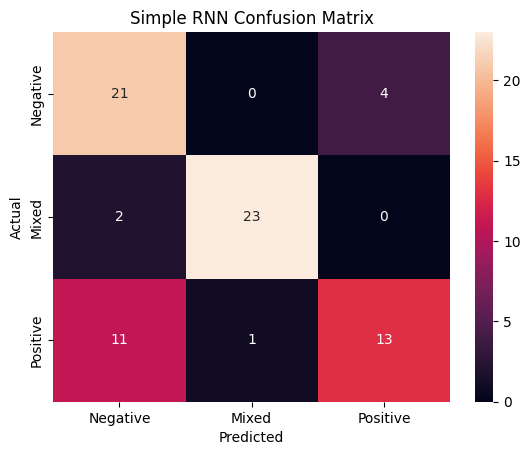

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict test data
y_pred_prob = rnn_model.predict(X_test_pad)

y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Negative", "Mixed", "Positive"],
    zero_division=0
))

# Macro F1
macro_f1 = f1_score(
    y_test, y_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

# Mixed class F1
mixed_f1 = f1_score(
    y_test, y_pred,
    labels=[1],
    average="macro",
    zero_division=0
)

print("Macro F1 Score:", macro_f1)
print("Mixed F1 Score:", mixed_f1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Mixed", "Positive"],
    yticklabels=["Negative", "Mixed", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Simple RNN Confusion Matrix")
plt.show()

# **LSTM**

In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(32, dropout=0.3, recurrent_dropout=0.2),

    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.5),

    Dense(3, activation="softmax")
])

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_lstm_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_lstm = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=16,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.3211 - loss: 1.1300
Epoch 1: val_loss improved from None to 1.12418, saving model to best_lstm_model.keras

Epoch 1: finished saving model to best_lstm_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 15s 154ms/step - accuracy: 0.3400 - loss: 1.1281 - val_accuracy: 0.5200 - val_loss: 1.1242 - learning_rate: 0.0010
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.4769 - loss: 1.1191
Epoch 2: val_loss improved from 1.12418 to 1.11189, saving model to best_lstm_model.keras

Epoch 2: finished saving model to best_lstm_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.4800 - loss: 1.1165 - val_accuracy: 0.6000 - val_loss: 1.1119 - learning_rate: 0.0010
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.6559 - loss: 1.0953
Epoch 3: val_loss improved from 1.11189 to 1.07852, saving model to best_lstm_model.keras

Epoch 3: finished saving model to best_lstm_model.keras
19/19 ━━━━━━━━━━━━━━━━━━

In [19]:
import numpy as np
from sklearn.metrics import classification_report, f1_score, accuracy_score

y_pred_prob_lstm = lstm_model.predict(X_test_pad)

y_pred_lstm = np.argmax(y_pred_prob_lstm, axis=1)

print("LSTM Classification Report:")

print(classification_report(
    y_test,
    y_pred_lstm,
    labels=[0, 1, 2],
    target_names=["Negative", "Mixed", "Positive"],
    zero_division=0
))

lstm_accuracy = accuracy_score(y_test, y_pred_lstm)

lstm_macro_f1 = f1_score(
    y_test, y_pred_lstm,
    average="macro",
    labels=[0, 1, 2],
    zero_division=0
)

lstm_mixed_f1 = f1_score(
    y_test, y_pred_lstm,
    labels=[1],
    average="macro",
    zero_division=0
)

print("LSTM Accuracy:", lstm_accuracy)
print("LSTM Macro F1:", lstm_macro_f1)
print("LSTM Mixed F1:", lstm_mixed_f1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 455ms/step
LSTM Classification Report:
              precision    recall  f1-score   support

    Negative       0.53      0.64      0.58        25
       Mixed       0.57      0.80      0.67        25
    Positive       0.80      0.32      0.46        25

    accuracy                           0.59        75
   macro avg       0.63      0.59      0.57        75
weighted avg       0.63      0.59      0.57        75

LSTM Accuracy: 0.5866666666666667
LSTM Macro F1: 0.5685425685425686
LSTM Mixed F1: 0.6666666666666666


**GRU**

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

gru_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    GRU(
        32,
        dropout=0.3,
        recurrent_dropout=0.2
    ),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.5),

    Dense(3, activation="softmax")
])

gru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_gru_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_gru = gru_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=16,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],
    verbose=1
)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.3173 - loss: 1.1301
Epoch 1: val_loss improved from None to 1.12289, saving model to best_gru_model.keras

Epoch 1: finished saving model to best_gru_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.3533 - loss: 1.1276 - val_accuracy: 0.3867 - val_loss: 1.1229 - learning_rate: 0.0010
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4021 - loss: 1.1163
Epoch 2: val_loss improved from 1.12289 to 1.11203, saving model to best_gru_model.keras

Epoch 2: finished saving model to best_gru_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.4200 - loss: 1.1142 - val_accuracy: 0.5600 - val_loss: 1.1120 - learning_rate: 0.0010
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5318 - loss: 1.0946
Epoch 3: val_loss improved from 1.11203 to 1.08994, saving model to best_gru_model.keras

Epoch 3: finished saving model to best_gru_model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 71

In [22]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    f1_score,
    accuracy_score
)

y_pred_prob_gru = gru_model.predict(X_test_pad)

y_pred_gru = np.argmax(y_pred_prob_gru, axis=1)

print("GRU Classification Report:")

print(classification_report(
    y_test,
    y_pred_gru,
    labels=[0, 1, 2],
    target_names=["Negative", "Mixed", "Positive"],
    zero_division=0
))

gru_accuracy = accuracy_score(y_test, y_pred_gru)

gru_macro_f1 = f1_score(
    y_test,
    y_pred_gru,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

gru_mixed_f1 = f1_score(
    y_test,
    y_pred_gru,
    labels=[1],
    average="macro",
    zero_division=0
)

print("GRU Accuracy:", gru_accuracy)
print("GRU Macro F1:", gru_macro_f1)
print("GRU Mixed F1:", gru_mixed_f1)

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 705ms/step
GRU Classification Report:
              precision    recall  f1-score   support

    Negative       0.60      0.84      0.70        25
       Mixed       0.88      0.92      0.90        25
    Positive       0.79      0.44      0.56        25

    accuracy                           0.73        75
   macro avg       0.76      0.73      0.72        75
weighted avg       0.76      0.73      0.72        75

GRU Accuracy: 0.7333333333333333
GRU Macro F1: 0.7220211161387633
GRU Mixed F1: 0.9019607843137255


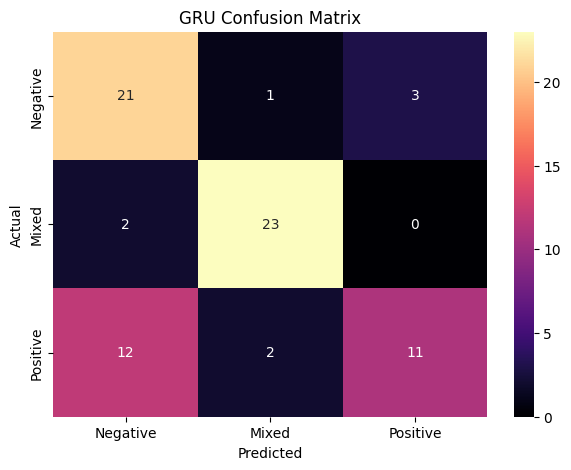

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_gru,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="magma",
    xticklabels=["Negative", "Mixed", "Positive"],
    yticklabels=["Negative", "Mixed", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("GRU Confusion Matrix")

plt.show()